# Magnetometer data

Let's try an example where we use the higher-level methods provided by `junopy` to read
and plot magnetometer data for a specific interval.

In [1]:
import datetime as dt
import numpy as np
from matplotlib import pyplot as plt

from junopy import config
from junopy import mag
from junopy import utils

config.ConfigVars.set_root(".junodata")    # <---- Change as necessary

Importing Library
done


`junopy` provides a convenient method in the `junopy.mag` module to load magnetometer data between
two times.  These times do not need to be the same date, `junopy` will read and merge files in the 
background, providing you with one `MagData` object that contains all data.  Since all data is 
loaded onto your RAM, use this with caution.

In [2]:
start = dt.datetime(2020, 1, 1, 2)
stop = dt.datetime(2020, 1, 1, 23)

mag_data = mag.load_mag_data(start, stop, coordsystem="JUNO_JSS")
mag_data.df


Downloaded: /home/ysar/code/junopy/docs/examples/.junodata/data/mag/2020/001/fgm_jno_l3_2020001ss_r1s_v01.sts


,DecD,Bx,By,Bz,Brange,X,Y,Z,Bmag,R,LT,Latitude,Br,Btheta,Bphi
time,,,,,,,,,,,,,,,
2020-01-01 02:00:00.509,1.083339,9.46,0.16,3.96,0.0,-3469430.969,-344736.164,-2417260.778,10.256647,4.242516e+06,0.378300,-34.734227,-10.005460,2.118287,0.776160
2020-01-01 02:00:01.509,1.083351,9.48,0.12,3.98,0.0,-3469435.843,-344736.209,-2417262.983,10.282276,4.242521e+06,0.378300,-34.734214,-10.029961,2.110935,0.817941
2020-01-01 02:00:02.509,1.083362,9.49,0.17,3.98,0.0,-3469440.716,-344736.253,-2417265.189,10.292201,4.242527e+06,0.378299,-34.734201,-10.042203,2.119419,0.769173
2020-01-01 02:00:03.509,1.083374,9.50,0.15,3.95,0.0,-3469445.589,-344736.298,-2417267.394,10.289558,4.242532e+06,0.378299,-34.734188,-10.031663,2.148614,0.790063
2020-01-01 02:00:04.509,1.083386,9.48,0.17,3.92,0.0,-3469450.462,-344736.342,-2417269.599,10.259907,4.242537e+06,0.378298,-34.734175,-9.999840,2.163054,0.768182
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-01-01 22:59:55.539,1.958282,9.40,0.47,3.22,0.0,-3822270.261,-346114.562,-2573230.958,9.947326,4.620721e+06,0.344943,-33.840957,-9.604089,2.562546,0.379636
2020-01-01 22:59:56.539,1.958293,9.43,0.50,3.21,0.0,-3822274.734,-346114.557,-2573232.888,9.973916,4.620726e+06,0.344942,-33.840946,-9.625584,2.588995,0.352463
2020-01-01 22:59:57.539,1.958305,9.39,0.50,3.20,0.0,-3822279.206,-346114.552,-2573234.818,9.932880,4.620731e+06,0.344942,-33.840935,-9.586928,2.575115,0.348855


Using SPICE, `junopy` has already calculated `Br, Btheta, Bphi` for this data range.  Notice that the index is of type `datetime`, 
this means that you can use a lot of `pandas` capability to resample this data, say if you wanted to look at a lower cadence of 
1 hour.  For example - 

In [3]:
mag_data.df.resample('1h').mean().head()   # <-- Only for show, this does not modify the dataframe in place.

,DecD,Bx,By,Bz,Brange,X,Y,Z,Bmag,R,LT,Latitude,Br,Btheta,Bphi
time,,,,,,,,,,,,,,,
2020-01-01 02:00:00,1.104167,9.318411,0.259181,4.004978,0.0,-3.478188e+06,-344814.670624,-2.421220e+06,10.146334,4.251940e+06,0.377440,-34.711126,-9.924273,2.002724,0.661380
2020-01-01 03:00:00,1.145833,9.181564,0.297683,4.110622,0.0,-3.495657e+06,-344965.180439,-2.429107e+06,10.064515,4.270736e+06,0.375729,-34.665181,-9.877315,1.832725,0.605452
2020-01-01 04:00:00,1.187500,9.234311,0.061847,4.248231,0.0,-3.513053e+06,-345105.937324,-2.436943e+06,10.165478,4.289444e+06,0.374032,-34.619636,-9.981407,1.728506,0.841238
2020-01-01 05:00:00,1.229042,9.275482,-0.292385,4.292420,0.0,-3.530323e+06,-345236.646762,-2.444704e+06,10.225482,4.308010e+06,0.372354,-34.574618,-10.013497,1.688186,1.193759
2020-01-01 06:00:00,1.270833,9.354006,-0.623100,4.192686,0.0,-3.547625e+06,-345358.603959,-2.452462e+06,10.270266,4.326602e+06,0.370679,-34.529714,-9.996713,1.788934,1.526489


Where you can see that the data has been re-binned into 1 hour cadence, very easily.  This ability of `pandas` `DataFrame` to use `datetime` indexes
is exploited often in the `junopy` code for different instruments.  For more details, see [`pandas.DatetimeIndex`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DatetimeIndex.html).

## Plot the data using `matplotlib`

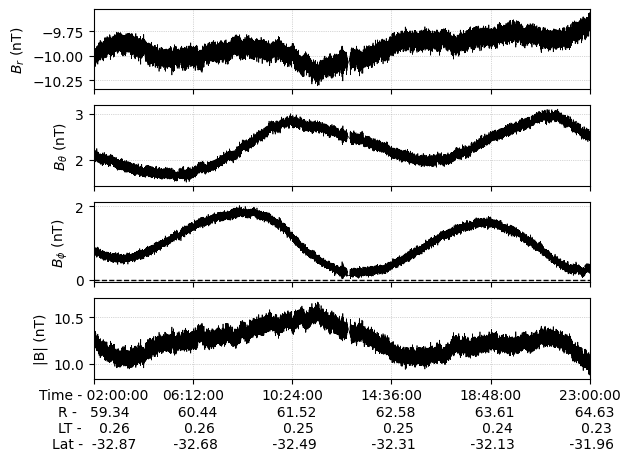

In [4]:
fig, axs = plt.subplots(4, 1, sharex=True)

tick_times, tick_strings = utils.plot.find_ticks_between(start, stop, nticks=6)
mag_data.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs, lw=0.5)

for a in axs:
    a.set_xlim([tick_times[0], tick_times[-1]])
    a.xaxis.set_ticks(tick_times, tick_strings)
    a.label_outer()